# 05 · Showcase

Results of the n-tuple network: learning curves from the training logs (A), then evaluation
and replays (B, added later). All logic lives in `src/analysis/`; this notebook only calls it.

In [1]:
%load_ext autoreload
%autoreload 2

import platform

from analysis import curves

assert platform.machine() == "arm64", platform.machine()

## A · Learning curves

Reads `logs/<run>.csv` for the three overnight runs (one row per 1,000 games); no training or
evaluation. Raw rows are drawn faintly, a trailing `WINDOW`-row mean on top (20 rows = the
last 20k games); the log-x plot uses log-binned means instead. Every figure is saved to
`figures/` as PNG and SVG.

figures/curves_avg_score_vs_games.png  figures/curves_avg_score_vs_games.svg
figures/curves_avg_score_vs_games_logx.png  figures/curves_avg_score_vs_games_logx.svg
figures/curves_reach_rates_vs_games.png  figures/curves_reach_rates_vs_games.svg
figures/curves_avg_moves_vs_games.png  figures/curves_avg_moves_vs_games.svg
figures/curves_max_score_vs_games.png  figures/curves_max_score_vs_games.svg
figures/curves_avg_score_vs_hours.png  figures/curves_avg_score_vs_hours.svg


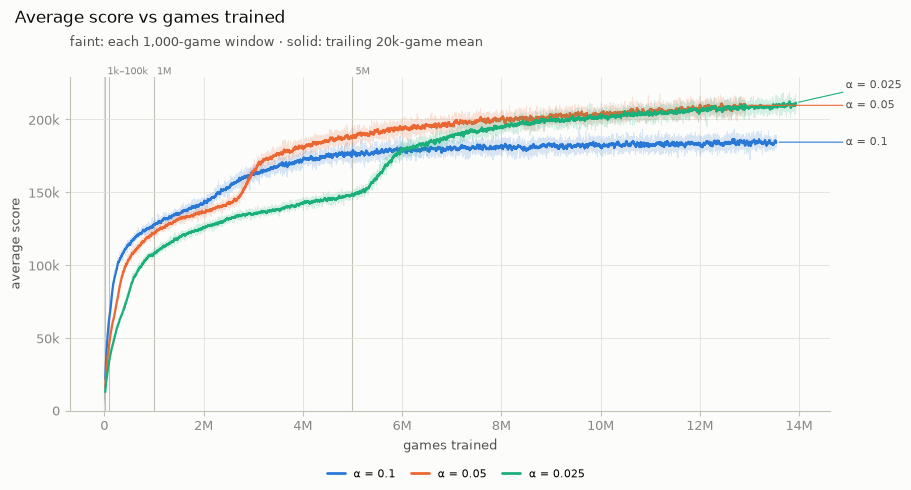

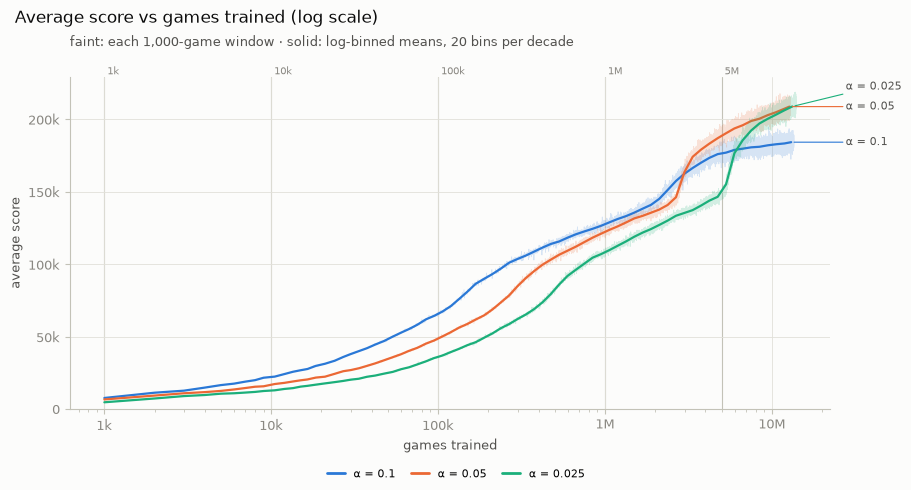

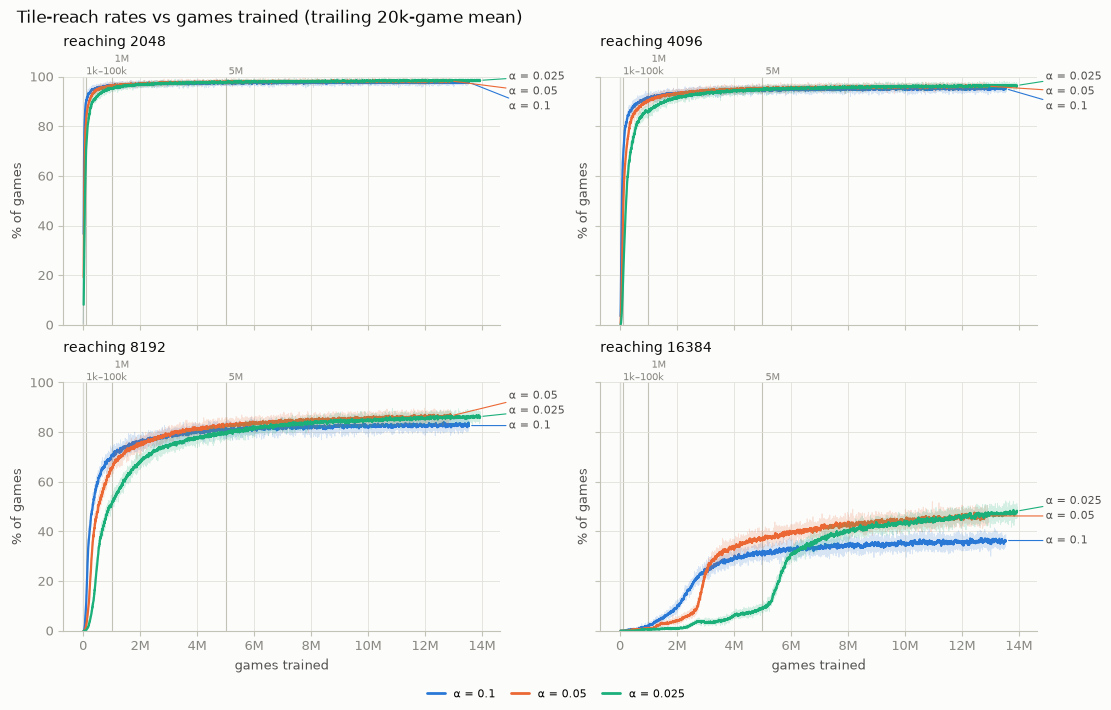

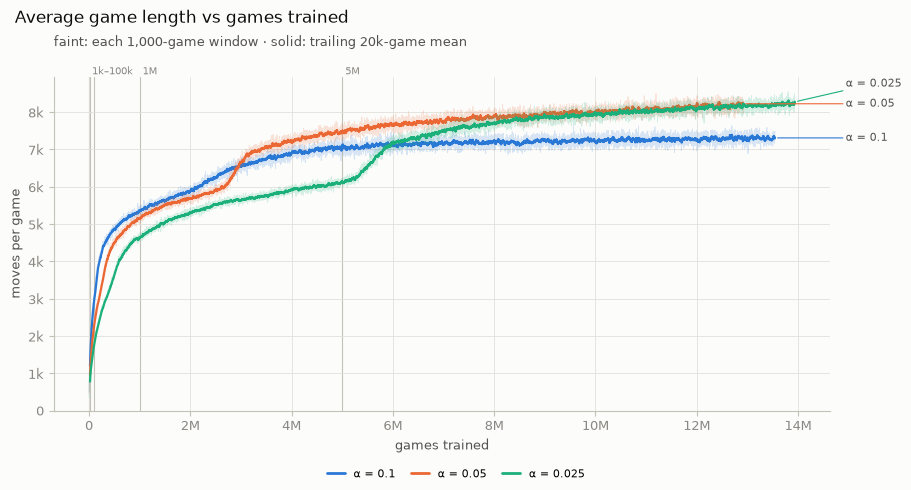

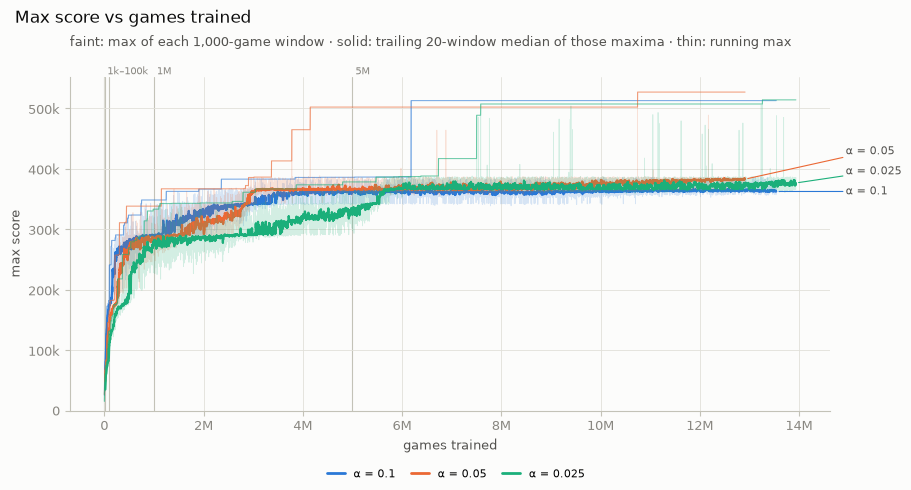

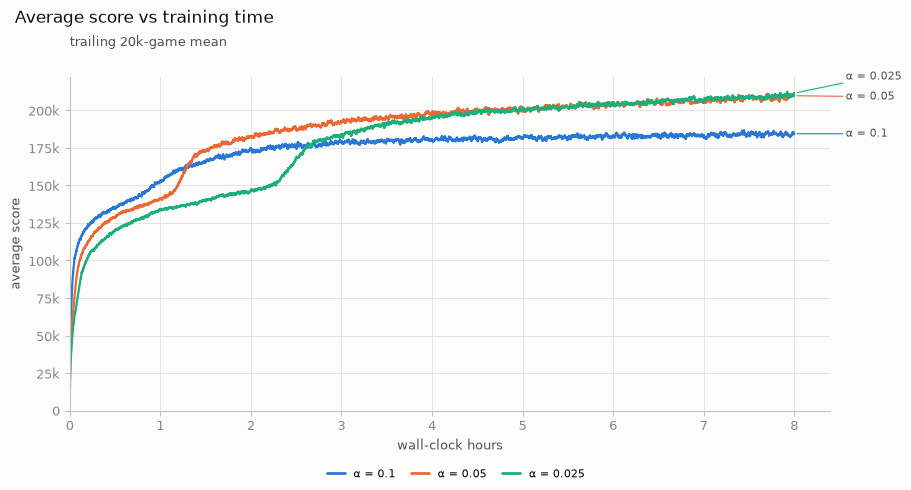

In [2]:
WINDOW = 20  # rows of 1,000 games

figs, table = curves.make_all(window=WINDOW)
for name in figs:
    print(f"figures/{name}.png  figures/{name}.svg")

Per run: averages over the last `WINDOW` rows, and the first game count at which the trailing
`WINDOW`-row mean of the 16384 reach rate exceeded 20%.

In [3]:
print(curves.format_summary(table))

last 20 rows (20k games); reach = % of games reaching the tile
run               alpha       games  hours  avg score   2048   4096   8192  16384   16384 > 20% first at
overnight-a01       0.1  13,541,000   8.00    184,274  97.7%  95.1%  82.6%  36.3%   2,607,000 games (1.08 h)
overnight-a005     0.05  12,912,000   8.00    209,571  98.2%  96.2%  86.5%  46.2%   2,930,000 games (1.27 h)
overnight-a0025   0.025  13,936,000   8.00    211,269  98.5%  96.4%  86.3%  48.2%   5,571,000 games (2.45 h)


## B · Evaluation

Reads `results/eval/` (written by `python -m ntuple.evaluate`, see `TRAINING.md`); no games are
played here. Policies: `random`, `greedy` (expectimax depth 0, the training policy) and
`expectimax-d1/d2/d3` (depth = chance layers; d1 and d2 are exact, d3 prunes branches with
reach probability < 1e-4). Game i uses seed i for every policy and checkpoint. Intervals are
95%: mean ± 1.96·s/√n for scores, Wilson for reach rates.

In [4]:
from analysis import report, stats

MAIN_RUN = "overnight-a0025"  # confirmed by the paired comparison below
results = report.load_results()
table = report.summary()
cols = ["run", "checkpoint", "games_trained", "policy", "depth", "games", "mean_score",
        "mean_lo", "mean_hi", "reach_8192", "reach_16384", "reach_32768", "count_32768",
        "corner_frac", "corner_stable_frac", "ms_per_move", "ms_per_move_bench"]
table[[c for c in cols if c in table]].round(3)

,run,checkpoint,games_trained,policy,depth,games,mean_score,mean_lo,mean_hi,reach_8192,reach_16384,reach_32768,count_32768,corner_frac,corner_stable_frac,ms_per_move,ms_per_move_bench
0,-,-,0,random,0,10000,1092.908,1082.414,1103.402,0.000,0.000,0.000,0,0.121,0.067,0.000,NaN
1,overnight-a0025,games-0000001000,1000,greedy,0,10000,6330.231,6271.969,6388.493,0.000,0.000,0.000,0,0.101,0.087,0.000,NaN
2,overnight-a0025,games-0000010000,10000,greedy,0,10000,13073.209,12966.629,13179.789,0.000,0.000,0.000,0,0.105,0.097,0.000,NaN
3,overnight-a0025,games-0000100000,100000,greedy,0,10000,36166.916,35825.983,36507.848,0.260,0.000,0.000,0,0.120,0.117,0.000,NaN
4,overnight-a0025,games-0001000000,1000000,greedy,0,10000,106127.835,105133.856,107121.814,49.920,0.500,0.000,0,0.514,0.513,0.000,NaN
5,overnight-a0025,games-0005000000,5000000,greedy,0,10000,148049.690,146939.166,149160.213,80.180,8.790,0.000,0,0.692,0.690,0.001,NaN
6,overnight-a0025,final,13936900,expectimax,1,10000,287020.512,285491.879,288549.145,97.100,79.580,0.060,6,0.836,0.835,0.010,0.006
7,overnight-a0025,final,13936900,expectimax,2,3000,320821.867,318535.319,323108.414,99.167,90.533,0.233,7,0.854,0.852,0.148,0.124
8,overnight-a0025,final,13936900,expectimax,3,300,333272.440,325808.679,340736.201,99.000,92.667,1.000,3,0.859,0.857,1.830,1.874
9,overnight-a0025,final,13936900,greedy,0,10000,211474.292,209683.606,213264.979,86.570,48.300,0.000,0,0.780,0.779,0.000,0.000


### Which run is the main model

Greedy on the final checkpoints, paired by seed: score difference (95% CI) and 16384-rate
difference are reported together; if they point in opposite directions it says DISAGREE and
the choice is left to a human.

In [5]:
print(stats.format_comparison(report.compare("overnight-a005", "overnight-a0025")))

overnight-a005 vs overnight-a0025, 10,000 paired games (same seeds)
  mean score        205,998 vs    211,474   diff -5,477  95% CI [-8,024, -2,930]  -> overnight-a0025
  reach 16384      44.88% vs     48.30%   diff -3.42 pp  95% CI [-4.81, -2.03]  -> overnight-a0025
  winner: overnight-a0025


### Strength vs games trained

Greedy at every milestone plus the final checkpoint (the last point, hollow marker).

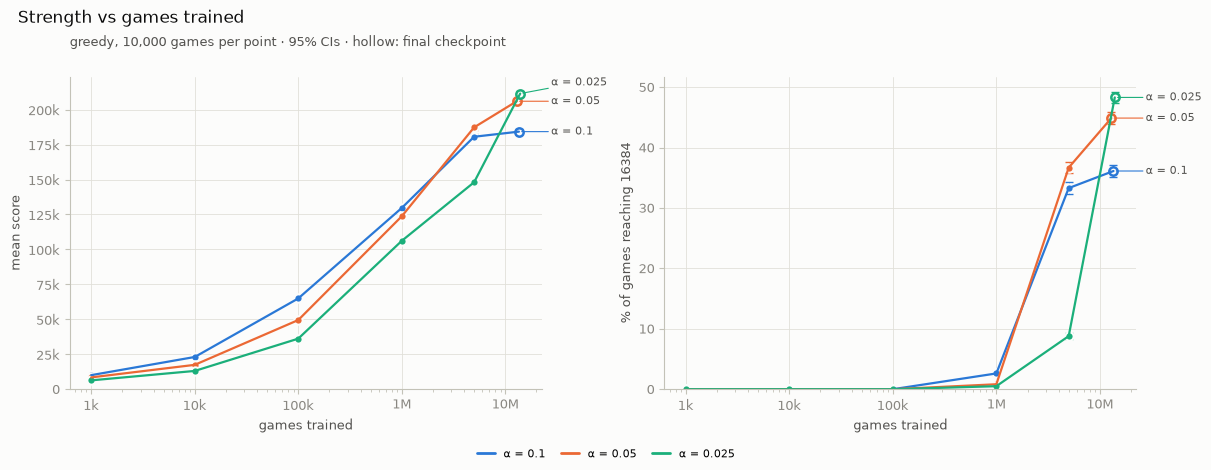

In [6]:
fig = report.plot_progression(table)
curves.save_figure(fig, "eval_progression_greedy");

### Main model: policies compared

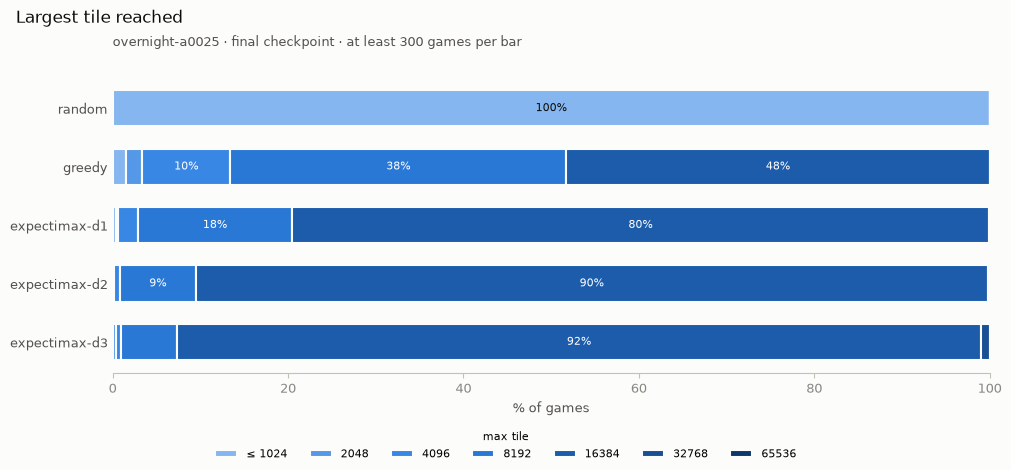

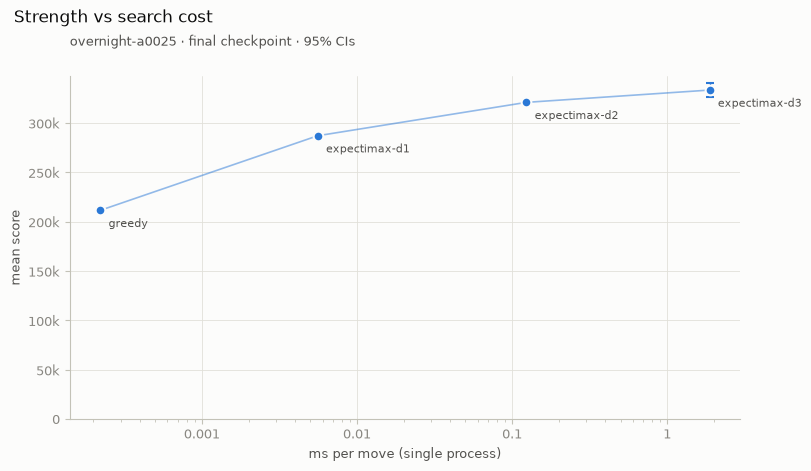

In [7]:
fig = report.plot_max_tile_distribution(table, MAIN_RUN)
curves.save_figure(fig, f"eval_max_tile_{MAIN_RUN}")
fig = report.plot_strength_vs_cost(table, MAIN_RUN)
curves.save_figure(fig, f"eval_strength_vs_cost_{MAIN_RUN}");

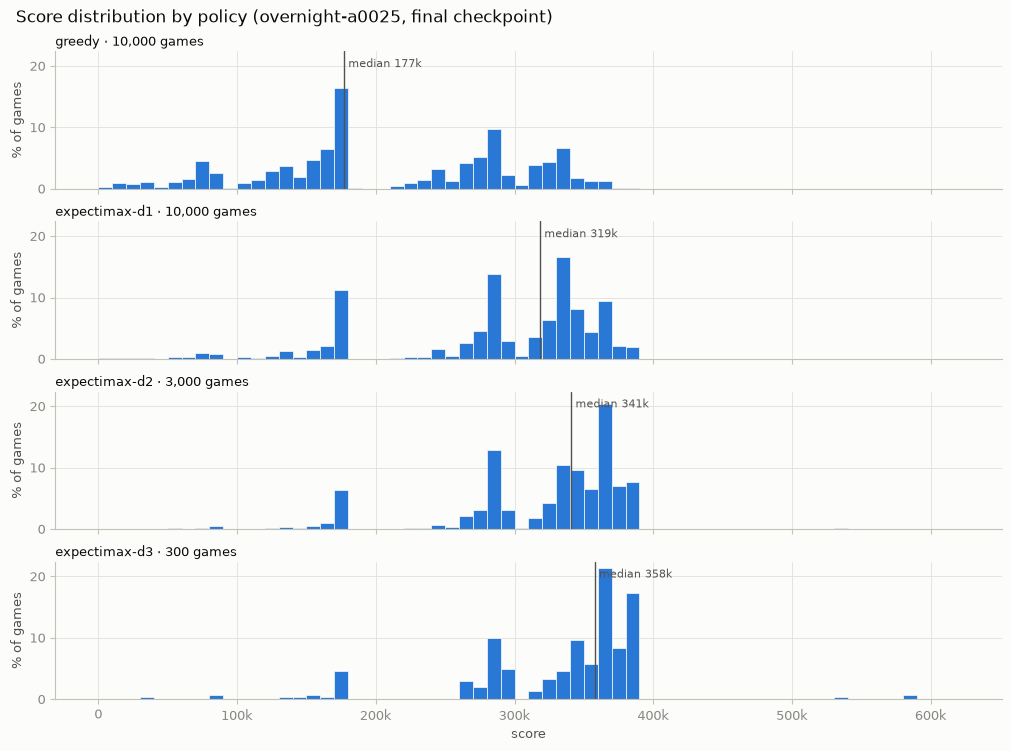

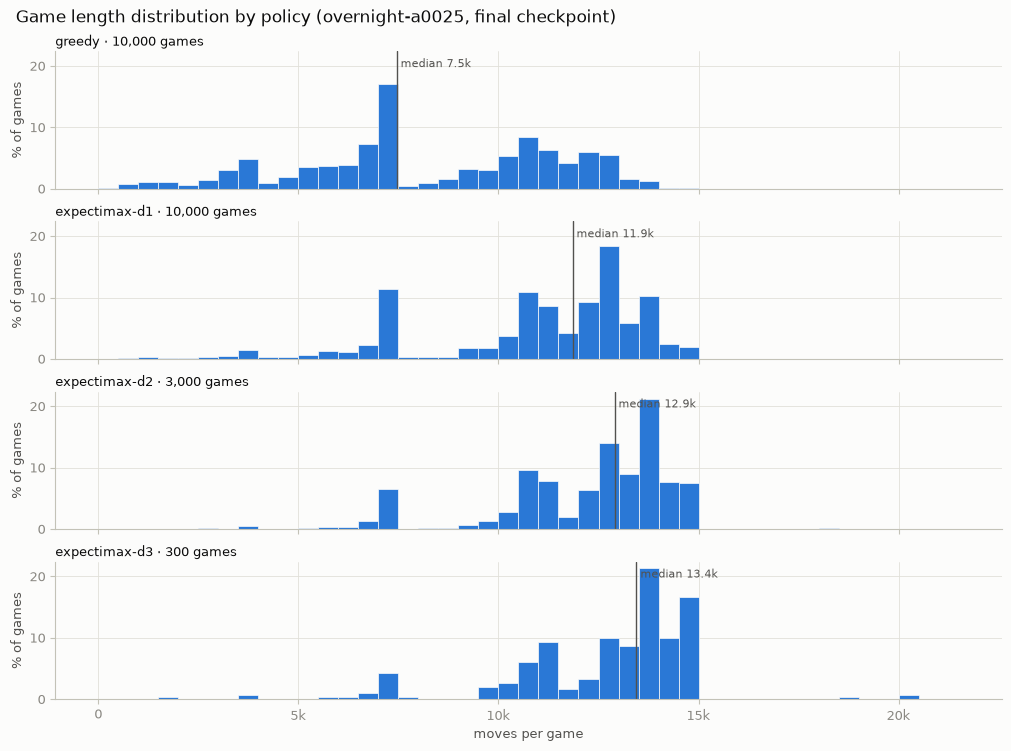

In [8]:
fig = report.plot_distributions(results, MAIN_RUN, "score")
curves.save_figure(fig, f"eval_score_hist_{MAIN_RUN}")
fig = report.plot_distributions(results, MAIN_RUN, "moves")
curves.save_figure(fig, f"eval_game_length_{MAIN_RUN}");

Where the largest tile ends on the final board. The weights are shared across all 8
rotations/reflections, so no corner is preferred and a roughly even spread over the 4 corners
is expected.

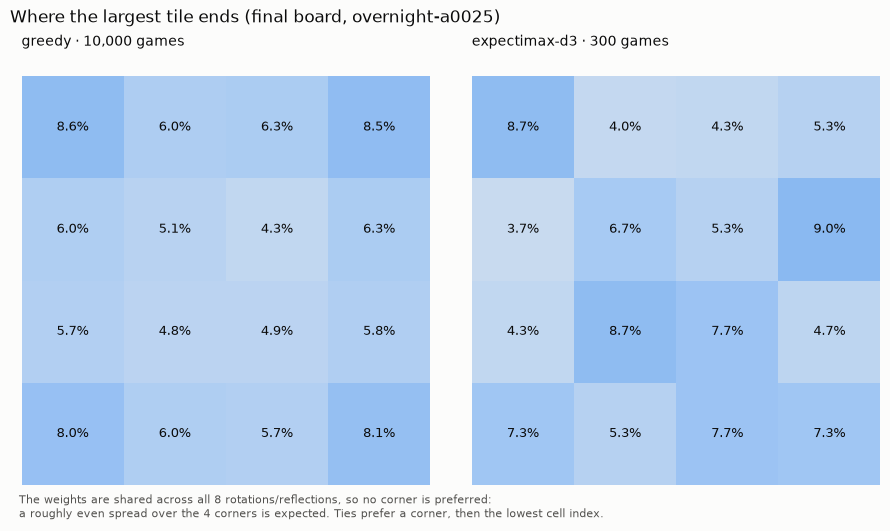

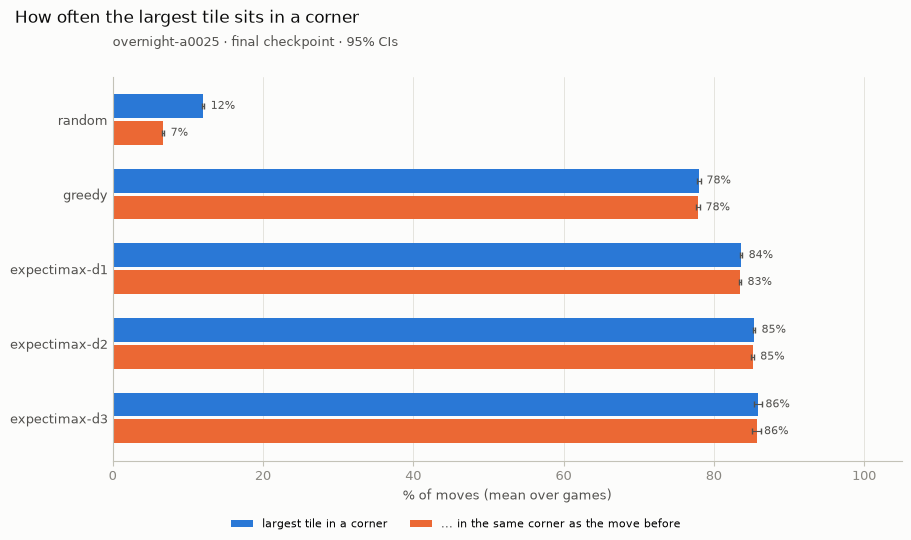

In [9]:
best = report.best_expectimax(table, MAIN_RUN)
fig = report.plot_max_tile_heatmap(results, MAIN_RUN, ["greedy", best])
curves.save_figure(fig, f"eval_max_tile_heatmap_{MAIN_RUN}")
fig = report.plot_corner_frac(table, MAIN_RUN)
curves.save_figure(fig, f"eval_corner_frac_{MAIN_RUN}");

### Headline numbers

`results/summary.json`: the main run's training and every policy on its final checkpoint;
`python -m analysis.readme` builds the README tables from the same data.

In [10]:
import json

path = report.write_headline(MAIN_RUN)
head = json.loads(path.read_text())
b = head["best"]
print(f"{path}\nbest policy {head['best_policy']}: {b['mean_score']:,.0f} "
      f"[{b['mean_lo']:,.0f}, {b['mean_hi']:,.0f}] over {b['games']:,} games, "
      f"16384 {b['reach']['16384']['pct']:.1f}%, 32768 in {b['count_32768']} games")

/Users/ardacakil/Desktop/2048-bot/results/summary.json
best policy expectimax-d3: 333,272 [325,809, 340,736] over 300 games, 16384 92.7%, 32768 in 3 games


## C · Replays

Files in `results/replays/` (written by `python -m ntuple.replays`); drag the slider to step
through a game.

In [11]:
from ntuple.replays import REPLAY_ROOT

replays = sorted(REPLAY_ROOT.glob("*.json"))
for i, p in enumerate(replays):
    print(i, p.name)

0 overnight-a0025_final_expectimax-d1_best_seed9630.json
1 overnight-a0025_final_expectimax-d2_best_seed312.json
2 overnight-a0025_final_expectimax-d3_best_seed56.json
3 overnight-a0025_final_expectimax-d3_median_seed113.json
4 overnight-a0025_final_greedy_best_seed5438.json
5 overnight-a0025_final_greedy_median_seed127.json
6 random_best_seed2577.json


In [12]:
report.replay_viewer(next(p for p in replays if f"_{best}_best_" in p.name));

overnight-a0025 final expectimax-d3 seed 56: score 581,648, max tile 32,768, 20,286 moves (best)


interactive(children=(IntSlider(value=0, description='step', layout=Layout(width='600px'), max=20286), Output(…